# 08 — Statistical and machine-learning models on validation (Week 3, Sprint 2)

AutoARIMA, AutoETS (statsforecast) and LightGBM (tuned with Optuna), scored on the **validation** split with the
shared module `src/evaluation/metrics.py`, on exactly the same samples as notebook 07. The test split stays closed.

**AutoARIMA / AutoETS.** Order (ARIMA) or model form (ETS: additive error, no season) and parameters are chosen once
on the last `FIT_DAYS` days of train (short gaps ≤ 60 min linearly interpolated for fitting only; a longer gap
shortens the segment). The fitted model then runs forward over train tail + validation as a **causal filter with
fixed parameters**: at each origin t the state is updated with P(t) and the forecast for t + h is read off the
state (`src/models/statespace.py`; invalid minutes are skipped, not filled). No re-fitting per origin (42k origins
per horizon would make that impractical); no daily season (m = 1,440 is infeasible for these methods and the daily
cycle is weak, notebook 05).

**LightGBM.** Direct model per horizon on the change P(t + h) − P(t), features from
`src/models/tabular_features.py`: 59 lags, minute-mod-5, hour sin/cos, level relative to L24 (`gbm`, univariate
arm) and the same plus covariate changes and allocation gap (`gbm_cov`, covariate arm). Optuna (TPE, `N_TRIALS`
trials or `STUDY_TIMEOUT` seconds per study) minimises validation MAE with early stopping on validation; the best
setting is refitted with three seeds (mean ± sd reported; seed-0 forecasts used in the tables).
Selection on validation makes validation scores slightly optimistic; the fair comparison is on test at the end.

**References** from notebook 07 (read from `reports/baselines/val_predictions.parquet`): persistence,
`pers_mod5_rolling`, `ar_lags_cal`, `ar_lags_cal_cov`.

| Cell | Content | Needs |
|---|---|---|
| 1 | Setup, paths, packages, settings | — |
| 2 | Load the dataset, sample indices, notebook-07 references | 1 |
| 3 | Fitting segment for AutoARIMA / AutoETS | 2 |
| 4 | AutoARIMA: fit, check, rolling forecasts | 3 |
| 5 | AutoETS: fit, check, rolling forecasts | 3 |
| 6 | LightGBM: Optuna tuning per horizon and arm | 2 |
| 7 | LightGBM: refit with three seeds, feature importance | 6 |
| 8 | Comparison on validation, Diebold–Mariano, covariate arm | 4, 5, 7 |
| 9 | Figure: skill per model and horizon | 8 |
| 10 | Save tables, predictions, summary | 8 |
| 11 | Summary | 8, 10 |

Export after saving (Cmd+S): `%run ../src/tools/nb_outputs_to_md.py 08_classical_models.ipynb`.


In [1]:
# One-off repair: install lightgbm and make libomp.dylib available inside the kernel's own environment
import sys, os, shutil, subprocess, glob
from pathlib import Path
PREFIX = Path(sys.prefix)
TARGET = PREFIX / "lib" / "libomp.dylib"
def run(cmd):
    print("$", " ".join(map(str, cmd)))
    r = subprocess.run(list(map(str, cmd)), capture_output=True, text=True)
    print((r.stdout + r.stderr)[-1500:])
    return r.returncode

print("python:", sys.executable)
run([sys.executable, "-m", "pip", "install", "lightgbm"])

if not TARGET.exists():
    cands = [shutil.which("conda"), "/opt/miniconda3/bin/conda", "/opt/miniconda3/condabin/conda",
             str(Path.home() / "miniconda3/bin/conda"), str(Path.home() / "anaconda3/bin/conda"),
             "/opt/homebrew/Caskroom/miniconda/base/bin/conda"]
    conda = next((c for c in cands if c and Path(c).exists()), None)
    print("conda found:", conda)
    if conda:
        run([conda, "install", "-y", "-p", PREFIX, "-c", "conda-forge", "llvm-openmp"])

if not TARGET.exists():
    print("conda route did not provide libomp; using the copy bundled with scikit-learn")
    run([sys.executable, "-m", "pip", "install", "scikit-learn"])
    import sklearn
    found = glob.glob(str(Path(sklearn.__file__).parent / ".dylibs" / "libomp*.dylib"))
    print("bundled:", found)
    if found:
        shutil.copy2(found[0], TARGET)

print("libomp in environment:", TARGET.exists(), TARGET)

python: /opt/miniconda3/envs/dcpower/bin/python
$ /opt/miniconda3/envs/dcpower/bin/python -m pip install lightgbm

libomp in environment: True /opt/miniconda3/envs/dcpower/lib/libomp.dylib


In [2]:
# Cell 1: setup, paths, packages, settings (needed by every cell)
import sys, json, time, platform, importlib, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
missing = [m for m in ("statsforecast", "statsmodels", "lightgbm", "optuna") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(f"install first (Terminal, env dcpower): pip install {' '.join(missing)}")
import statsforecast, statsmodels, lightgbm as lgb, optuna
from statsforecast.models import AutoARIMA, AutoETS
from evaluation import metrics as M
from models import statespace as SS
from models import tabular_features as TF

DATA = ROOT / "data" / "processed" / "model_dataset.parquet"
META = ROOT / "data" / "processed" / "model_dataset_meta.json"
REF = ROOT / "reports" / "baselines" / "val_predictions.parquet"
OUT = ROOT / "reports" / "classical"
FIG = ROOT / "reports" / "figures" / "classical"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

HORIZONS = (1, 5, 15)
SPLIT_EVAL = "val"
DM_LAG = 60
FIT_DAYS = 14             # AutoARIMA / AutoETS fitting segment (days at the end of train)
MAX_INTERP_GAP = 60       # minutes; longer invalid gaps shorten the fitting segment
N_TRIALS = 15             # Optuna trials per (horizon, arm)
STUDY_TIMEOUT = 300       # seconds per study (whichever comes first)
MAX_ROUNDS = 3000
SEEDS = (0, 1, 2)
REF_MODELS = ["persistence", "pers_mod5_rolling", "ar_lags_cal", "ar_lags_cal_cov"]

pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(240); pl.Config.set_fmt_str_lengths(300)
import warnings
warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")
optuna.logging.set_verbosity(optuna.logging.WARNING)
for p in (DATA, META, REF, ROOT / "src" / "models" / "statespace.py", ROOT / "src" / "models" / "tabular_features.py"):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p.relative_to(ROOT)}")
print(f"python {platform.python_version()} | polars {pl.__version__} | numpy {np.__version__} | statsforecast "
      f"{statsforecast.__version__} | statsmodels {statsmodels.__version__} | lightgbm {lgb.__version__} | optuna {optuna.__version__}")


OK      data/processed/model_dataset.parquet
OK      data/processed/model_dataset_meta.json
OK      reports/baselines/val_predictions.parquet
OK      src/models/statespace.py
OK      src/models/tabular_features.py
python 3.11.16 | polars 1.44.2 | numpy 2.4.6 | statsforecast 2.1.1 | statsmodels 0.15.0 | lightgbm 4.7.0 | optuna 5.0.0


In [3]:
# Cell 2: dataset, sample indices, notebook-07 references (needs cell 1)
md = pl.read_parquet(DATA)
meta = json.loads(META.read_text())
n = md.height
A = TF.arrays(md)
P = A["P"]
VALID = md["valid"].to_numpy()
L24 = A["L24"]
MOD5 = A["MOD5"]
EP = md["minute_epoch"].to_numpy()
THR = {h: meta["thresholds"][str(h)]["rel_p95"] for h in HORIZONS}
I_TR, I_VA = int(meta["split"]["i_tr"]), int(meta["split"]["i_va"])
IDX = {}
for h in HORIZONS:
    ok = md[f"ok_h{h}"].to_numpy()
    sp = np.array(md[f"split_h{h}"].to_list(), dtype=object)
    IDX[h] = {s: np.flatnonzero(ok & (sp == s)) for s in ("train", "val")}
print(f"rows {n:,} | builder {meta['version']} | val samples:", {h: len(IDX[h]["val"]) for h in HORIZONS})

ref = pl.read_parquet(REF)
PRED = {h: {} for h in HORIZONS}
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    for m in REF_MODELS:
        r = ref.filter((pl.col("h") == h) & (pl.col("model") == m))
        assert np.array_equal(r["minute_epoch"].to_numpy(), EP[t]), f"notebook 07 samples differ (h={h}, {m}): re-run 07"
        PRED[h][m] = r["yhat"].to_numpy()
print("notebook-07 references loaded and aligned:", REF_MODELS)
TIMES = {}


rows 303,840 | builder 1.1 (2026-10-08) | val samples: {1: 42575, 5: 42567, 15: 42547}
notebook-07 references loaded and aligned: ['persistence', 'pers_mod5_rolling', 'ar_lags_cal', 'ar_lags_cal_cov']


In [4]:
# Cell 3: fitting segment for AutoARIMA / AutoETS (needs cell 2)
lo = max(0, I_TR - FIT_DAYS * 1440)
seg_valid = VALID[lo:I_TR]
# runs of invalid minutes inside the segment
inv = ~seg_valid
edges = np.diff(np.r_[0, inv.astype(np.int8), 0])
starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
long_gaps = [(s, e) for s, e in zip(starts, ends) if e - s > MAX_INTERP_GAP]
S0 = int(lo + (long_gaps[-1][1] if long_gaps else int(np.argmax(seg_valid))))
y_fit = np.where(VALID[S0:I_TR], P[S0:I_TR], np.nan)
k = np.arange(len(y_fit))
fin = np.isfinite(y_fit)
n_interp = int((~fin).sum())
y_fit = np.interp(k, k[fin], y_fit[fin])
print(f"fitting segment: {md['minute_local'][S0]} .. {md['minute_local'][I_TR - 1]} | {len(y_fit):,} minutes "
      f"({len(y_fit) / 1440:.1f} days) | interpolated {n_interp} minutes | long gaps cut: {len(long_gaps)}")
if len(y_fit) < 3 * 1440:
    print("WARNING: segment shorter than 3 days")

# series the fitted models run over: from S0 to the last validation target, invalid minutes as NaN (no filling)
last = int(max(IDX[h][SPLIT_EVAL].max() + h for h in HORIZONS))
y_run = np.where(VALID[S0:last + 1], P[S0:last + 1], np.nan)
print(f"filter series: {len(y_run):,} minutes, NaN {np.isnan(y_run).sum():,}")


fitting segment: 2021-07-17 00:00:00 .. 2021-07-29 16:47:00 | 18,288 minutes (12.7 days) | interpolated 0 minutes | long gaps cut: 1
filter series: 63,864 minutes, NaN 2,940


In [5]:
# Cell 4: AutoARIMA (statsforecast) on the segment, then a fixed-parameter Kalman filter over validation (needs cell 3)
t0 = time.time()
arima = AutoARIMA(seasonal=False, allowdrift=False, allowmean=False).fit(y_fit)
order, params, names = SS.arima_spec(arima.model_)
TIMES["autoarima_fit_s"] = time.time() - t0
print(f"AutoARIMA order (p, d, q) = {order} | fit {TIMES['autoarima_fit_s']:.1f} s | AICc {arima.model_['aicc']:.1f}")
print("parameters:", {k: round(float(v), 4) for k, v in zip(names, params)})

# check: one-step predictions of the state-space version equal statsforecast's fitted values on the segment
_, one = SS.arima_rolling(y_fit, order, params, np.array([0]), [1])
fit_sf = arima.predict_in_sample()["fitted"]
burn = 500
print(f"check one-step vs statsforecast fitted (after {burn} min burn-in): max abs diff "
      f"{np.nanmax(np.abs(one[burn:] - fit_sf[burn:])):.2e} kW")

t0 = time.time()
orig = {h: IDX[h][SPLIT_EVAL] - S0 for h in HORIZONS}
all_orig = np.unique(np.concatenate(list(orig.values())))
fc, _ = SS.arima_rolling(y_run, order, params, all_orig, HORIZONS)
for h in HORIZONS:
    PRED[h]["auto_arima"] = fc[h][np.searchsorted(all_orig, orig[h])]
    y = P[IDX[h][SPLIT_EVAL] + h]
    print(f"h={h:>2}: MAE {M.mae(y, PRED[h]['auto_arima']):.4f} kW (persistence {M.mae(y, PRED[h]['persistence']):.4f})")
TIMES["autoarima_filter_s"] = time.time() - t0


AutoARIMA order (p, d, q) = (1, 1, 5) | fit 4.9 s | AICc 24875.0
parameters: {'ar.L1': -0.3969, 'ma.L1': 0.1615, 'ma.L2': -0.1832, 'ma.L3': -0.2339, 'ma.L4': -0.2454, 'ma.L5': 0.1547, 'sigma2': 0.2281}
check one-step vs statsforecast fitted (after 500 min burn-in): max abs diff 1.09e-08 kW
h= 1: MAE 0.2838 kW (persistence 0.2866)
h= 5: MAE 0.4180 kW (persistence 0.4299)
h=15: MAE 0.5885 kW (persistence 0.6048)


In [6]:
# Cell 5: AutoETS (additive error, no season) on the segment, then fixed-parameter recursion over validation (needs cell 3)
t0 = time.time()
ets = AutoETS(model="AZN", season_length=1).fit(y_fit)
spec = SS.ets_spec(ets.model_)
TIMES["autoets_fit_s"] = time.time() - t0
print(f"AutoETS model {spec['components']} | fit {TIMES['autoets_fit_s']:.1f} s | AICc {ets.model_['aicc']:.1f}")
print({k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in spec.items()})
_, fit_e = SS.ets_rolling(y_fit, spec, np.array([0]), [1])
print(f"check recursion vs statsforecast fitted: max abs diff {np.max(np.abs(fit_e - ets.predict_in_sample()['fitted'])):.2e} kW")

fc, _ = SS.ets_rolling(y_run, spec, all_orig, HORIZONS)
for h in HORIZONS:
    PRED[h]["auto_ets"] = fc[h][np.searchsorted(all_orig, orig[h])]
    y = P[IDX[h][SPLIT_EVAL] + h]
    print(f"h={h:>2}: MAE {M.mae(y, PRED[h]['auto_ets']):.4f} kW (persistence {M.mae(y, PRED[h]['persistence']):.4f})")


AutoETS model ANNN | fit 0.4 s | AICc 155174.1
{'alpha': 0.6957, 'beta': 0.0, 'phi': 0.0, 'l0': 35.0651, 'b0': 0.0, 'trend': False, 'damped': False, 'components': 'ANNN'}
check recursion vs statsforecast fitted: max abs diff 7.11e-15 kW
h= 1: MAE 0.2778 kW (persistence 0.2866)
h= 5: MAE 0.4178 kW (persistence 0.4299)
h=15: MAE 0.5930 kW (persistence 0.6048)


In [7]:
# Cell 6: LightGBM, Optuna tuning per horizon and arm on validation MAE (needs cell 2)
def lgb_params(trial_params, seed):
    p = {"metric": "l1", "verbosity": -1, "num_threads": 0, "bagging_freq": 1, "seed": seed,
         "bagging_seed": seed, "feature_fraction_seed": seed, "deterministic": True, "force_row_wise": True}
    p.update(trial_params)
    return p

def space(trial):
    return {"objective": trial.suggest_categorical("objective", ["regression", "regression_l1", "huber"]),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
            "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 2000, log=True),
            "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
            "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
            "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 10.0, log=True)}

DATA_LGB, TUNE = {}, {}
for h in HORIZONS:
    tr, va = IDX[h]["train"], IDX[h][SPLIT_EVAL]
    for arm in ("gbm", "gbm_cov"):
        Xtr, names = TF.features(A, tr, arm)
        Xva, _ = TF.features(A, va, arm)
        ytr, yva = P[tr + h] - P[tr], P[va + h] - P[va]
        dtr = lgb.Dataset(Xtr, ytr, feature_name=names, params={"feature_pre_filter": False}, free_raw_data=False)
        dva = lgb.Dataset(Xva, yva, reference=dtr, free_raw_data=False)
        DATA_LGB[(h, arm)] = (dtr, dva, Xva, names)

        def objective(trial):
            b = lgb.train(lgb_params(space(trial), 0), dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva],
                          callbacks=[lgb.early_stopping(100, verbose=False)])
            trial.set_user_attr("rounds", b.best_iteration)
            return M.mae(yva, b.predict(Xva, num_iteration=b.best_iteration))

        t0 = time.time()
        st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
        st.optimize(objective, n_trials=N_TRIALS, timeout=STUDY_TIMEOUT)
        TUNE[(h, arm)] = {"params": st.best_params, "rounds": st.best_trial.user_attrs["rounds"],
                          "val_MAE_change": st.best_value, "trials": len(st.trials), "s": time.time() - t0}
        print(f"h={h:>2} {arm:8s}: {len(st.trials):>3} trials, {time.time() - t0:6.0f} s | best MAE of change "
              f"{st.best_value:.4f} kW | rounds {TUNE[(h, arm)]['rounds']} | {st.best_params}")


h= 1 gbm     :  15 trials,    144 s | best MAE of change 0.2491 kW | rounds 692 | {'objective': 'regression_l1', 'learning_rate': 0.02523965106709417, 'num_leaves': 56, 'min_data_in_leaf': 241, 'feature_fraction': 0.5371044513568065, 'bagging_fraction': 0.8859056902990231, 'lambda_l2': 0.09849759569524298}
h= 1 gbm_cov :  15 trials,     88 s | best MAE of change 0.2465 kW | rounds 966 | {'objective': 'regression_l1', 'learning_rate': 0.056161972583919355, 'num_leaves': 26, 'min_data_in_leaf': 570, 'feature_fraction': 0.6435247769623673, 'bagging_fraction': 0.9949028979893475, 'lambda_l2': 0.7590410939827547}
h= 5 gbm     :  15 trials,    126 s | best MAE of change 0.3934 kW | rounds 646 | {'objective': 'regression_l1', 'learning_rate': 0.029827572824100364, 'num_leaves': 38, 'min_data_in_leaf': 199, 'feature_fraction': 0.6284400156137786, 'bagging_fraction': 0.951692187563174, 'lambda_l2': 0.28224321807470754}
h= 5 gbm_cov :  15 trials,    140 s | best MAE of change 0.3852 kW | rounds 

In [8]:
# Cell 7: LightGBM refit of the best setting with three seeds; feature importance (needs cell 6)
SEED_MAE, IMP, BOOST = {}, {}, {}
for (h, arm), tune in TUNE.items():
    dtr, dva, Xva, names = DATA_LGB[(h, arm)]
    va = IDX[h][SPLIT_EVAL]
    y = P[va + h]
    maes, preds = [], []
    for s in SEEDS:
        b = lgb.train(lgb_params(tune["params"], s), dtr, num_boost_round=max(tune["rounds"], 1))
        pr = P[va] + b.predict(Xva)
        maes.append(M.mae(y, pr)); preds.append(pr)
        if s == SEEDS[0]:
            BOOST[(h, arm)] = b
    name = "lightgbm" if arm == "gbm" else "lightgbm_cov"
    PRED[h][name] = preds[0]
    SEED_MAE[(h, name)] = (float(np.mean(maes)), float(np.std(maes, ddof=1)))
    gain = BOOST[(h, arm)].feature_importance("gain")
    IMP[(h, name)] = sorted(zip(names, gain / gain.sum()), key=lambda x: -x[1])
    print(f"h={h:>2} {name:13s}: MAE over seeds {np.mean(maes):.4f} ± {np.std(maes, ddof=1):.4f} kW "
          f"(seeds {', '.join(f'{m:.4f}' for m in maes)})")
print("\ntop 15 features by gain share, lightgbm_cov, h = 5:")
print(pl.DataFrame({"feature": [f for f, _ in IMP[(5, 'lightgbm_cov')][:15]],
                    "gain share": [round(float(g), 4) for _, g in IMP[(5, 'lightgbm_cov')][:15]]}))


h= 1 lightgbm     : MAE over seeds 0.2491 ± 0.0001 kW (seeds 0.2491, 0.2492, 0.2491)
h= 1 lightgbm_cov : MAE over seeds 0.2464 ± 0.0003 kW (seeds 0.2465, 0.2466, 0.2461)
h= 5 lightgbm     : MAE over seeds 0.3934 ± 0.0001 kW (seeds 0.3934, 0.3933, 0.3935)
h= 5 lightgbm_cov : MAE over seeds 0.3850 ± 0.0005 kW (seeds 0.3852, 0.3844, 0.3853)
h=15 lightgbm     : MAE over seeds 0.5659 ± 0.0004 kW (seeds 0.5654, 0.5662, 0.5662)
h=15 lightgbm_cov : MAE over seeds 0.5559 ± 0.0008 kW (seeds 0.5556, 0.5569, 0.5553)

top 15 features by gain share, lightgbm_cov, h = 5:
shape: (15, 2)
┌────────────────────┬────────────┐
│ feature            ┆ gain share │
│ ---                ┆ ---        │
│ str                ┆ f64        │
╞════════════════════╪════════════╡
│ d5_util_gpu_mean   ┆ 0.1707     │
│ lag1               ┆ 0.0639     │
│ lag2               ┆ 0.0624     │
│ lag3               ┆ 0.0543     │
│ lag4               ┆ 0.0387     │
│ d1_util_gpu_mean   ┆ 0.0385     │
│ lag10              ┆ 0.0

In [9]:
# Cell 8: comparison on validation; DM vs persistence and vs ar_lags_cal_cov; covariate arm (needs cells 4, 5, 7)
MODELS = REF_MODELS + ["auto_arima", "auto_ets", "lightgbm", "lightgbm_cov"]
res = []
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    y, p0 = P[t + h], P[t]
    ramp = md[f"ramp_h{h}"].to_numpy().astype(float)[t]
    for mname in MODELS:
        r = M.evaluate(y, PRED[h][mname], p0, l24=L24[t], ramp=ramp, thr=THR[h],
                       mod5_target=MOD5[t + h] if h == 1 else None, dm_lag=DM_LAG)
        d = M.dm_test(y, PRED[h][mname], PRED[h]["ar_lags_cal_cov"], lag=DM_LAG) if mname != "ar_lags_cal_cov" else {}
        sm = SEED_MAE.get((h, mname), (np.nan, np.nan))
        res.append({"h": h, "model": mname, **r, "DM_vs_ARcov_stat": d.get("DM_stat", np.nan),
                    "DM_vs_ARcov_p": d.get("DM_p", np.nan), "MAE_seed_mean": sm[0], "MAE_seed_sd": sm[1]})
VAL = pl.DataFrame(res)
show = ["h", "model", "MAE", "RMSE", "sMAPE", "R2_delta", "skill_MAE", "MAE_ramp", "MAE_normal", "ramp_recall",
        "ramp_F1", "DM_stat", "DM_p", "DM_vs_ARcov_stat", "DM_vs_ARcov_p"]
print(VAL.select(show).with_columns([pl.col(c).round(4) for c in show[2:]]))
print("\nh = 1, MAE without mod-0 targets:")
print(VAL.filter(pl.col("h") == 1).select("model", pl.col("MAE_no_mod0_target").round(4)))
rows = []
for h in HORIZONS:
    y = P[IDX[h][SPLIT_EVAL] + h]
    a, b = PRED[h]["lightgbm_cov"], PRED[h]["lightgbm"]
    d = M.dm_test(y, a, b, lag=DM_LAG)
    rows.append({"h": h, "LightGBM MAE": round(M.mae(y, b), 4), "LightGBM + cov MAE": round(M.mae(y, a), 4),
                 "rel. change": round(M.mae(y, a) / M.mae(y, b) - 1, 4), "DM stat": round(d["DM_stat"], 2), "DM p": d["DM_p"]})
COVARM = pl.DataFrame(rows)
print("\ncovariate arm, LightGBM:")
print(COVARM)
print("\nranking by validation MAE:")
print(VAL.sort("h", "MAE").group_by("h", maintain_order=True).agg(pl.col("model")).with_columns(
      pl.col("model").list.join(" < ")))


shape: (24, 15)
┌─────┬───────────────────┬────────┬────────┬────────┬──────────┬───────────┬──────────┬────────────┬─────────────┬─────────┬──────────┬────────┬──────────────────┬───────────────┐
│ h   ┆ model             ┆ MAE    ┆ RMSE   ┆ sMAPE  ┆ R2_delta ┆ skill_MAE ┆ MAE_ramp ┆ MAE_normal ┆ ramp_recall ┆ ramp_F1 ┆ DM_stat  ┆ DM_p   ┆ DM_vs_ARcov_stat ┆ DM_vs_ARcov_p │
│ --- ┆ ---               ┆ ---    ┆ ---    ┆ ---    ┆ ---      ┆ ---       ┆ ---      ┆ ---        ┆ ---         ┆ ---     ┆ ---      ┆ ---    ┆ ---              ┆ ---           │
│ i64 ┆ str               ┆ f64    ┆ f64    ┆ f64    ┆ f64      ┆ f64       ┆ f64      ┆ f64        ┆ f64         ┆ f64     ┆ f64      ┆ f64    ┆ f64              ┆ f64           │
╞═════╪═══════════════════╪════════╪════════╪════════╪══════════╪═══════════╪══════════╪════════════╪═════════════╪═════════╪══════════╪════════╪══════════════════╪═══════════════╡
│ 1   ┆ persistence       ┆ 0.2866 ┆ 0.511  ┆ 0.9163 ┆ -0.0     ┆ 0.0       ┆ 1

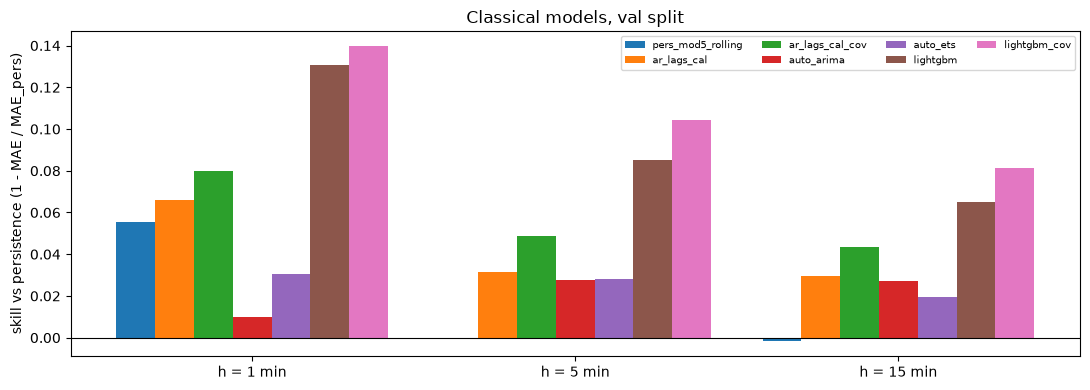

saved reports/figures/classical/01_skill_val.png


In [10]:
# Cell 9: figure: skill vs persistence per model and horizon (needs cell 8)
fig, ax = plt.subplots(figsize=(11, 4))
mods = [m for m in MODELS if m != "persistence"]
w = 0.84 / len(mods)
for i, mname in enumerate(mods):
    v = [VAL.filter((pl.col("h") == h) & (pl.col("model") == mname))["skill_MAE"][0] for h in HORIZONS]
    ax.bar(np.arange(len(HORIZONS)) + (i - (len(mods) - 1) / 2) * w, v, w, label=mname)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(HORIZONS)), [f"h = {h} min" for h in HORIZONS])
ax.set_ylabel("skill vs persistence (1 - MAE / MAE_pers)")
ax.set_title(f"Classical models, {SPLIT_EVAL} split")
ax.legend(fontsize=7, ncol=4)
fig.tight_layout(); fig.savefig(FIG / "01_skill_val.png", dpi=130); plt.show()
print("saved", (FIG / "01_skill_val.png").relative_to(ROOT))


In [11]:
# Cell 10: save tables, predictions and a summary (needs cell 8)
VAL.write_csv(OUT / "val_metrics.csv")
COVARM.write_csv(OUT / "val_covariate_arm_lightgbm.csv")
parts = []
for h in HORIZONS:
    t = IDX[h][SPLIT_EVAL]
    base = {"minute_epoch": EP[t], "h": np.full(len(t), h, np.int16), "y": P[t + h], "p0": P[t]}
    for mname in ("auto_arima", "auto_ets", "lightgbm", "lightgbm_cov"):
        parts.append(pl.DataFrame({**base, "model": [mname] * len(t), "yhat": PRED[h][mname]}))
pl.concat(parts).write_parquet(OUT / "val_predictions.parquet")
summary = {"split": SPLIT_EVAL, "dataset_builder": meta["version"], "dataset_input_sha256": meta["input"]["sha256"],
           "created": time.strftime("%Y-%m-%d %H:%M:%S"),
           "fit_segment": {"start": str(md["minute_local"][S0]), "end": str(md["minute_local"][I_TR - 1]),
                           "minutes": len(y_fit), "interpolated": n_interp},
           "auto_arima": {"order": order, "params": dict(zip(names, map(float, params))), "aicc": float(arima.model_["aicc"])},
           "auto_ets": {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in spec.items()},
           "lightgbm": {f"{h}|{arm}": v for (h, arm), v in TUNE.items()},
           "seed_mae": {f"{h}|{m}": v for (h, m), v in SEED_MAE.items()},
           "importance_top10": {f"{h}|{m}": [(f, float(g)) for f, g in imp[:10]] for (h, m), imp in IMP.items()},
           "times_s": TIMES, "metrics": VAL.to_dicts(), "covariate_arm": COVARM.to_dicts()}
(OUT / "classical_summary.json").write_text(json.dumps(summary, indent=1, default=str))
for f in ("val_metrics.csv", "val_covariate_arm_lightgbm.csv", "val_predictions.parquet", "classical_summary.json"):
    print(f"written reports/classical/{f} ({(OUT / f).stat().st_size / 2**20:.2f} MiB)")


written reports/classical/val_metrics.csv (0.01 MiB)
written reports/classical/val_covariate_arm_lightgbm.csv (0.00 MiB)
written reports/classical/val_predictions.parquet (7.95 MiB)
written reports/classical/classical_summary.json (0.03 MiB)


In [12]:
# Cell 11: summary (needs cells 8 and 10)
print(f"split {SPLIT_EVAL} | test not opened | AutoARIMA {order} | AutoETS {spec['components']}")
for h in HORIZONS:
    v = VAL.filter(pl.col("h") == h)
    pers = v.filter(pl.col("model") == "persistence")["MAE"][0]
    b = v.filter(pl.col("model") != "persistence").sort("MAE").row(0, named=True)
    c = COVARM.filter(pl.col("h") == h).row(0, named=True)
    print(f"h={h:>2}: persistence {pers:.4f} | best {b['model']} {b['MAE']:.4f} kW (skill {b['skill_MAE']:+.3f}) | "
          + " | ".join(f"{m} {v.filter(pl.col('model') == m)['skill_MAE'][0]:+.3f}" for m in ("auto_arima", "auto_ets", "lightgbm", "lightgbm_cov"))
          + f" | LightGBM covariates {c['rel. change']:+.2%} (DM p {c['DM p']:.2g})")


split val | test not opened | AutoARIMA (1, 1, 5) | AutoETS ANNN
h= 1: persistence 0.2866 | best lightgbm_cov 0.2465 kW (skill +0.140) | auto_arima +0.010 | auto_ets +0.031 | lightgbm +0.131 | lightgbm_cov +0.140 | LightGBM covariates -1.02% (DM p 0.0049)
h= 5: persistence 0.4299 | best lightgbm_cov 0.3852 kW (skill +0.104) | auto_arima +0.028 | auto_ets +0.028 | lightgbm +0.085 | lightgbm_cov +0.104 | LightGBM covariates -2.10% (DM p 7.9e-12)
h=15: persistence 0.6048 | best lightgbm_cov 0.5556 kW (skill +0.081) | auto_arima +0.027 | auto_ets +0.020 | lightgbm +0.065 | lightgbm_cov +0.081 | LightGBM covariates -1.74% (DM p 2.3e-10)


In [14]:
%run ../src/tools/nb_outputs_to_md.py 08_classical_models.ipynb

written 08_classical_models_outputs.md | code cells 14 | figures 1 in 08_classical_models_outputs_figures
